# gammaspec walkthrough: every function, in the order it is called

This notebook runs the pipeline step by step on the real 2021 NaI(Tl) data and shows, for
each function, **what goes in, what comes out, and how it works** (including the maths).

The order follows the data:

| Part | Step | What happens |
|---|---|---|
| A | 1. Ingestion | ASCII capture files → lossless integer codes → HDF5 store |
| B | 2. Characterisation | pulse template, analytic pulse model, noise |
| C | 3. Pre-processing | interference removal → pole-zero correction → baseline tracker |
| D | 4. Detection and events | optimal filter → successive cancellation → event list |
| E | 5–6. Pile-up resolution | TM, HYPER and least-squares fits on a real cluster; the pile-up solver in the pipeline |
| G | 7. Calibration and background subtraction | keV axis for each run, gain matching, net spectrum |
| F | Evaluation tools | how the numbers in the docs were measured |

Conventions: time is in **samples** (1 sample = 1/1.8 MHz = 0.556 µs) unless stated;
voltages are in volts; the raw pulses are negative and are flipped to positive early on.

*Rebuild with `python docs/build_walkthrough.py` (needs the local `data/` folder).*

In [1]:
import numpy as np, matplotlib.pyplot as plt, json, tempfile
from pathlib import Path
import gammaspec
from gammaspec import rawio, store, signal, template, noise, interference, baseline, preprocess, detect, events, pipeline, spectrum
from gammaspec import plotting as P
%matplotlib inline
np.set_printoptions(precision=5, suppress=False, linewidth=110, threshold=24, edgeitems=4)
ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
RAW = ROOT / "ADC_raw_output"
SRC_STORE = ROOT / "data/source_first100.h5"
BKG_STORE = ROOT / "data/background.h5"
TEMPLATE = ROOT / "data/characterization/background/template.h5"
TMP = Path(tempfile.mkdtemp())
FS = 1.8e6
print("gammaspec", gammaspec.__version__)

gammaspec 0.1.0


---
# Part A: Ingestion (step 1)

## A1. `rawio.read_header(path)`

**Called by:** `build_index` (for every file) and `read_raw_file`.
**Input:** a capture file path. **Output:** a `RawHeader`.

It reads only the first three lines (`Creation`, `Signals`, `Dt`), splits each at the first
colon, and converts: the timestamp with `datetime.fromisoformat`, the sample count as an
integer, and `Dt` with its unit (`ms` → × 10⁻³ s). It also records how many bytes the header
occupies, so the samples can be read starting right after it.

In [2]:
path = RAW / "raw_data_0.txt"
print("input: first 3 lines of", path.name)
with open(path, "rb") as f:
    for _ in range(3): print("   ", f.readline())
h = rawio.read_header(path)
print("\noutput:", h)
print("duration_s =", h.duration_s, "  time_s =", h.time_s)

input: first 3 lines of raw_data_0.txt
    b'Creation: 2021-08-26 13:34:48.617564\n'
    b'Signals:  524288\n'
    b'Dt:       5.555555555555556e-04 ms\n'

output: RawHeader(path=WindowsPath('D:/GammaSpectroscopy/ADC_raw_output/raw_data_0.txt'), file_number=0, created=datetime.datetime(2021, 8, 26, 13, 34, 48, 617564), n_samples=524288, dt_s=5.555555555555555e-07, header_bytes=89)
duration_s = 0.2912711111111111   time_s = 1629984888.617564


## A2. `rawio.parse_samples(body)` → `_parse_fixed_width(body)`

**Input:** the bytes after the header. **Output:** float64 volts.

Every sample line has exactly 14 bytes: `+d.dddddde-dd\n`. Instead of parsing 524,288
strings one at a time, the bytes are viewed as a **matrix with 14 columns** (one row per
line) and decoded column-wise with array arithmetic:

$$\text{mantissa} = \sum_{i=0}^{6} d_i\,10^{6-i},\qquad
\text{exponent} = \pm(10e_1 + e_2) - 6,\qquad v = \pm\,\text{mantissa}\cdot 10^{\text{exponent}}$$

where $d_i$ are the 7 mantissa digits (column 1, then columns 3–8; column 2 is the `.`).
Digits are bytes minus `ord('0')` = 48. The function first checks every fixed column
(`.` at 2, `e` at 9, newline at 13, signs, digits). If anything does not match, it returns
`None`, and `parse_samples` falls back to a generic float parser.

In [3]:
raw = path.read_bytes()
body = raw[h.header_bytes:]
a = np.frombuffer(body, dtype=np.uint8).reshape(-1, 14)
print("input bytes, first 2 lines:", body[:28])
print("as a 14-column uint8 matrix (row 0):", a[0], "->", bytes(a[0]))
d = a[0, [1, 3, 4, 5, 6, 7, 8]].astype(int) - 48
print("mantissa digits:", d, " exponent sign:", chr(a[0, 10]), " exponent digits:", a[0, 11:13] - 48)
v = rawio.parse_samples(body)
print("\noutput volts:", v, " count:", v.size)

input bytes, first 2 lines: b'+3.390868e-04\n+2.458379e-03\n'
as a 14-column uint8 matrix (row 0): [ 43  51  46  51  57  48  56  54  56 101  45  48  52  10] -> b'+3.390868e-04\n'
mantissa digits: [3 3 9 0 8 6 8]  exponent sign: -  exponent digits: [0 4]

output volts: [0.00034 0.00246 0.00229 0.00034 ... 0.00415 0.00424 0.00644 0.00704]  count: 524288


## A3. `rawio.volts_to_codes(volts, lsb)`

**Input:** volts and the ADC step (LSB = 84.771697 µV). **Output:** int32 ADC codes.

$$\text{code} = \operatorname{rint}(v/\text{LSB}),\qquad
\text{residual} = \max|v/\text{LSB} - \text{code}|$$

The printed values are codes × LSB rounded to 7 significant digits, so the residual is
tiny (≤ 0.006 LSB). If it exceeds 0.02 LSB the file is not on this ADC grid and the
function raises an error. This check proves the conversion loses nothing.

In [4]:
codes = rawio.volts_to_codes(v, rawio.DEFAULT_LSB_VOLTS)
x = v / rawio.DEFAULT_LSB_VOLTS
print("input  volts :", v[:6])
print("v / LSB      :", x[:6])
print("output codes :", codes[:6], codes.dtype)
print("max residual :", np.max(np.abs(x - codes)), "LSB   (code range", codes.min(), "to", codes.max(), ")")

input  volts : [ 3.39087e-04  2.45838e-03  2.28884e-03  3.39087e-04  7.62945e-04 -8.47717e-05]
v / LSB      : [ 4. 29. 27.  4.  9. -1.]
output codes : [ 4 29 27  4  9 -1] int32
max residual : 0.005473064913530834 LSB   (code range -65103 to 3783 )


## A4. `rawio.read_raw_file(path, lsb)`
Combines A1–A3: header → seek past it → parse → check the count → codes (or volts if
`lsb=None`). This is what each conversion worker runs.

In [5]:
h2, c2 = rawio.read_raw_file(path)
print("output:", h2.n_samples, "samples; codes", c2[:5], "; identical to A3:", np.array_equal(c2, codes))

output: 524288 samples; codes [ 4 29 27  4  9] ; identical to A3: True


## A5. `rawio.estimate_lsb(volts)` (for unknown hardware)

**Input:** volts. **Output:** the ADC step.

1. Near zero the printed values keep full precision, so the spacing between the smallest
   distinct |values| gives a first guess.
2. Refine with least squares over progressively larger values (bound × 8 each pass):
   $$\text{LSB} \leftarrow \frac{\sum_i v_i k_i}{\sum_i k_i^2},\qquad k_i = \operatorname{rint}(v_i/\text{LSB})$$
   Each pass only includes values where rounding to the right code is still unambiguous.

In [6]:
print("estimated LSB:", rawio.estimate_lsb(v), " built-in:", rawio.DEFAULT_LSB_VOLTS)

estimated LSB: 8.47716969775423e-05  built-in: 8.4771697e-05


## A6. `rawio.build_index(directory)` and `write_index_csv`

**Input:** a folder. **Output:** all headers **sorted by timestamp** (the file numbers in
the 2021 data are scrambled relative to time; see ADR-0002).

In [7]:
idx = rawio.build_index(RAW)
print("captures:", len(idx))
for hh in idx[:5]:
    print(f"   file {hh.file_number:5d}  created {hh.created}")
print("file numbers of the first 8 in time order:", [hh.file_number for hh in idx[:8]])

captures: 4786
   file     0  created 2021-08-26 13:34:48.617564
   file   302  created 2021-08-26 13:34:50.906028
   file   404  created 2021-08-26 13:34:53.152647
   file  1774  created 2021-08-26 13:34:55.175131
   file  2883  created 2021-08-26 13:34:57.018127
file numbers of the first 8 in time order: [0, 302, 404, 1774, 2883, 3020, 3156, 3293]


## A7. `store.convert(headers, out_path)` and `store.CaptureStore`

**Input:** headers (time order). **Output:** one HDF5 file: `/codes` (int32, one row per
capture, gzip + shuffle), `/index/*` (time, file number, path) and attributes (LSB, Δt).
Parsing runs in parallel worker processes (`_read_codes`); one process writes.

`CaptureStore(path)` reads it back: `codes(i)`, `volts(i) = codes × LSB`, `live_time_s`.
(Here we open the store built earlier rather than converting again.)

In [8]:
with store.CaptureStore(SRC_STORE) as s:
    print("captures:", len(s), " samples/capture:", s.n_samples, " LSB:", s.lsb_volts, " dt:", s.dt_s)
    print("live time:", s.live_time_s, "s")
    print("capture 0 source:", s.source[0], " file number:", s.file_number[0])
    print("codes(0)[:5] =", s.codes(0)[:5], " identical to the text file:", np.array_equal(s.codes(0), codes))
    print("volts(0)[:5] =", s.volts(0)[:5])

captures: 100  samples/capture: 524288  LSB: 8.4771697e-05  dt: 5.555555555555555e-07
live time: 29.12711111111111 s
capture 0 source: ADC_raw_output\raw_data_0.txt  file number: 0
codes(0)[:5] = [ 4 29 27  4  9]  identical to the text file: True
volts(0)[:5] = [0.00034 0.00246 0.00229 0.00034 0.00076]


---
# Part B: Characterisation (step 2)

We use capture 1 of the ⁶⁰Co run as the running example.

## B1. `signal.to_positive(volts, polarity=-1)`
Multiplies by −1, so pulses point up. Then the capture median is subtracted (in
`characterize.scan`).

In [9]:
with store.CaptureStore(SRC_STORE) as s:
    volts1 = s.volts(1)
x1 = signal.to_positive(volts1)
x1 = x1 - np.median(x1)
print("input min/max:", volts1.min(), volts1.max(), " -> output min/max:", x1.min(), x1.max())

input min/max: -4.353196184344 0.225068855535  -> output min/max: -0.223882051777 4.354382988102


## B2. `signal.robust_sigma(x)` and `signal.noise_sigma(x)`

* `robust_sigma`: $\hat\sigma = 1.4826\cdot\operatorname{median}|x-\operatorname{median}(x)|$.
  For Gaussian noise the median absolute deviation is 0.6745 σ (1/0.6745 = 1.4826).
  Outliers such as pulses barely move a median.
* `noise_sigma`: robust σ of the **first differences** divided by √2. For white noise
  $\operatorname{Var}(x_n - x_{n-1}) = 2\sigma^2$. Differencing removes slow baseline changes
  and the undershoot, and pulses are rare outliers. It uses the central 131,072 samples.

In [10]:
print("plain std           :", x1.std())
print("robust_sigma(x)     :", signal.robust_sigma(x1))
print("noise_sigma(x)      :", signal.noise_sigma(x1))

plain std           : 0.027680427398760744
robust_sigma(x)     : 0.0027650153953883995
noise_sigma(x)      : 0.0014219353717558835


## B3. `signal.edge_signal(x, gap=2, avg=3)`

$$d[n] = x[n] - \tfrac{1}{3}\left(x[n-4] + x[n-3] + x[n-2]\right)$$

This is the rise relative to a short average ending 2 samples earlier. The pulse rises in
1–2 samples, so a half-risen sample stays out of the reference. On a slowly falling tail
d is small or negative, so the trigger does not fire on decays. The average is computed
with a cumulative sum (cs[i+3] − cs[i]) / 3.

In [11]:
sig1 = signal.noise_sigma(x1)
pk = signal.find_pulses(x1, sig1, 8)
p0 = int(pk[10])
e1 = signal.edge_signal(x1)
seg = slice(p0 - 6, p0 + 8)
print("x[n] around a pulse     :", np.round(x1[seg], 4))
print("edge_signal d[n] (same) :", np.round(e1[seg], 4))

x[n] around a pulse     : [ 0.0001 -0.0019 -0.0006 -0.0019 -0.0007  0.08    0.0947  0.082   0.0739  0.065   0.0546  0.0473  0.0406
  0.0343]
edge_signal d[n] (same) : [ 0.0013 -0.0001  0.0005 -0.001   0.0001  0.0815  0.0958  0.0562  0.0159 -0.0205 -0.0289 -0.0263 -0.0239
 -0.0213]


## B4. `signal.find_pulses(x, sigma, threshold)`

Fires where the edge signal exceeds `threshold` × its noise. Its noise is
$\sigma\sqrt{1 + 1/3}$ (one sample minus a 3-sample average). Each trigger is moved to
the highest sample within the next 4 samples, the peak.

In [12]:
print("input: sigma =", sig1, " threshold = 8")
print("output: ", pk.size, "pulse peaks; first:", pk[:8])
print("rate:", pk.size / (x1.size / FS), "per second")

input: sigma = 0.0014219353717558835  threshold = 8
output:  1215 pulse peaks; first: [ 454  967 1398 2103 2155 2293 2633 3700]
rate: 4171.3714599609375 per second


## B5. `signal.isolated(peaks, pre, post, n)` and `signal.pulse_free_mask(n, peaks, pre, post)`

* `isolated`: True where no other pulse lies within `pre` samples before or `post` after
  (and the window fits in the capture). Uses the gaps `diff(peaks)`.
* `pulse_free_mask`: True for samples at least `pre` before and `post` after every pulse.
  It marks +1 at each pulse's start of exclusion and −1 at its end, takes a cumulative sum,
  and keeps samples where the sum is 0. That is linear time, with no loops.

In [13]:
iso = signal.isolated(pk, 300, 300, x1.size)
free = signal.pulse_free_mask(x1.size, pk, 20, 1500)
print("isolated (±300):", iso.sum(), "of", pk.size, "   pulse-free samples (20 before, 1500 after):", free.mean().round(3))

isolated (±300): 312 of 1215    pulse-free samples (20 before, 1500 after): 0.026


## B6. `template.extract_windows(x, peaks, pre, post)`
One row per pulse: `x[p-pre : p+post+1]`, built with a single fancy-index (`peaks[:,None] + arange`).

In [14]:
W = template.extract_windows(x1, pk[iso], 40, 300)
print("output shape:", W.shape, " (pulses × samples); row 0 around the peak:", np.round(W[0, 38:44], 4))

output shape: (312, 341)  (pulses × samples); row 0 around the peak: [0.001  0.1317 0.2491 0.2326 0.2052 0.1795]


## B7. `template.fit_pulses(windows, template, pre, ...)`

Fits each window as $w(j) = A\,s(j - \delta) + b$ over $j \in [-10, 60]$
(A = amplitude, δ = sub-sample peak position, b = baseline).

For a **fixed δ** the model is linear in A and b. Least squares has a closed form: with
$S_{ss}=\sum s^2,\ S_s=\sum s,\ S_{sy}=\sum s y,\ S_y=\sum y,\ n$ samples,

$$A = \frac{n S_{sy} - S_s S_y}{n S_{ss} - S_s^2},\qquad
b = \frac{S_{ss} S_y - S_s S_{sy}}{n S_{ss} - S_s^2},\qquad
\text{SSE} = \sum y^2 - A S_{sy} - b S_y$$

So: evaluate this for 33 trial δ ∈ [−1, 1] (all pulses at once with one matrix product
$Y S^T$), take the best δ, refine it with a parabola through the three SSE values around
the minimum, then solve exactly at the refined δ. With `fit_baseline=False` (used after
baseline restoration) b = 0 and $A = S_{sy}/S_{ss}$.

In [15]:
T = template.PulseTemplate.load(TEMPLATE)
f = template.fit_pulses(W[:5].astype(float), T, 40)
print("input : 5 windows; peak samples", np.round(W[:5, 40], 4))
print("output: amplitude", np.round(f.amplitude, 4))
print("        shift δ  ", np.round(f.shift, 3), "(samples)")
print("        baseline ", np.round(f.baseline * 1e3, 3), "mV;  rms", np.round(f.rms * 1e3, 3), "mV")

input : 5 windows; peak samples [0.2491 0.1489 0.0821 0.223  0.2497]
output: amplitude [0.2512 0.1539 0.081  0.2245 0.2479]
        shift δ   [-0.075 -0.557  0.017 -0.029 -0.09 ] (samples)
        baseline  [ 2.283  1.469  1.179 -0.232  2.397] mV;  rms [1.397 1.301 1.224 1.484 1.158] mV


## B8. `template.build_template(windows, pre)`, with `_stack`, `_recentre`, `equalize_phase`

Pulses arrive at random sampling phases. Stacking many pulses at their *true* sub-sample
times samples the shape on a grid much finer than the ADC's (equivalent-time sampling).
Each iteration:

1. **`_stack`**: put every normalised sample $(w-b)/A$ at time $t = j - \delta$ into bins of
   1/16 sample; weighted average (weight $A^2$, the inverse variance of a normalised
   sample); light smoothing (none within ±3 samples of the peak); pre-pulse level set to 0.
2. **`_recentre`**: a parabola through the top three points finds the continuous maximum;
   shift it to t = 0 and scale it to 1.
3. **`fit_pulses`** with the new template; drop fits with rms > 3 × median (hidden pile-up).
4. **`equalize_phase`**: the true phases $\varphi = \delta \bmod 1$ are uniform, so map the
   fitted ones through their empirical CDF, $\varphi_i \to (\text{rank}_i + 0.5)/N$.
   Without this, a template warped inside each sample period plus correspondingly warped δ
   fit almost equally well (ADR-0004).

It stops when the template changes by less than 5 × 10⁻⁴ rms. Here we run it on the
isolated pulses of the background run (long isolation shows the whole undershoot).

In [16]:
with store.CaptureStore(BKG_STORE) as s:
    wins = []
    for i in range(20, 50):
        xb = signal.to_positive(s.volts(i)); xb = xb - np.median(xb)
        sb = signal.noise_sigma(xb); pb = signal.find_pulses(xb, sb, 5)
        ok = signal.isolated(pb, 1500, 1500, xb.size) & (xb[pb] > 30 * sb) & (xb[pb] < 4)
        wins.append(template.extract_windows(xb, pb[ok], 40, 1500))
Wb = np.concatenate(wins)
print("input:", Wb.shape[0], "isolated pulses, windows of", Wb.shape[1], "samples")
Tb, fb, used = template.build_template(Wb, 40, resolution=16, verbose=True)
print("output: template with", Tb.shape.size, "points at 1/16 sample, t from", Tb.t_start, "to", round(Tb.t_end, 2))
print("template at t = -2, -1, 0, 1, 5, 46 samples:", np.round(Tb(np.array([-2., -1, 0, 1, 5, 46])), 4))

input: 866 isolated pulses, windows of 1541 samples
  iter 0: used 812/866, median rms 0.00434 V, max change inf
  iter 1: used 783/866, median rms 0.00208 V, max change 9.07e-03
  iter 2: used 782/866, median rms 0.00206 V, max change 5.99e-04
  iter 3: used 782/866, median rms 0.00207 V, max change 1.36e-04
output: template with 24608 points at 1/16 sample, t from -38.9375 to 1499.0
template at t = -2, -1, 0, 1, 5, 46 samples: [-0.0011  0.2404  0.9995  0.9473  0.5359 -0.0427]


equalize_phase example: fitted phases [0.1  0.15 0.18 0.5  0.52 0.9 ] -> [0.083 0.25  0.417 0.583 0.75  0.917]


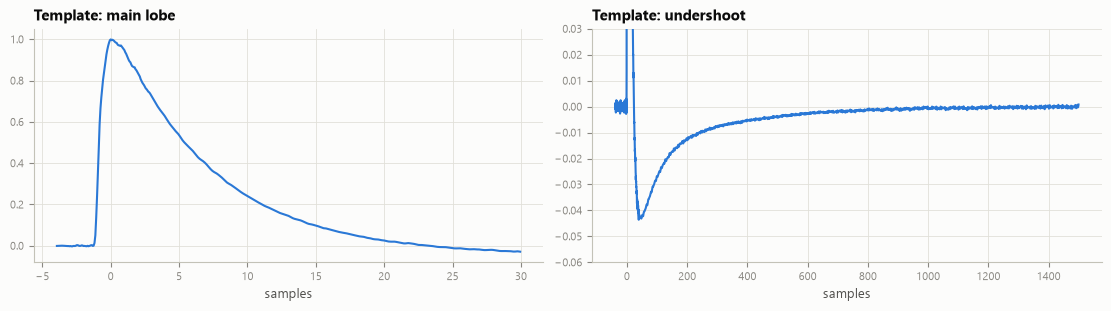

In [17]:
phi_before = np.mod(np.array([0.10, 0.15, 0.18, 0.5, 0.52, 0.9]), 1)
print("equalize_phase example: fitted phases", phi_before, "->", np.round(template.equalize_phase(phi_before), 3))
fig, ax = P.figure(1, 2, height_per_row=3.0)
ax[0,0].plot(Tb.t[(Tb.t>-4)&(Tb.t<30)], Tb.shape[(Tb.t>-4)&(Tb.t<30)]); ax[0,0].set_title("Template: main lobe"); ax[0,0].set_xlabel("samples")
ax[0,1].plot(Tb.t, Tb.shape); ax[0,1].set_ylim(-0.06, 0.03); ax[0,1].set_title("Template: undershoot"); ax[0,1].set_xlabel("samples")
plt.show()

## B9. `template.fit_multiexp(template)` with `multiexp_model` and `_exp_gauss`

The analytic model is a sum of exponentials starting at $t_0$, smoothed by a Gaussian of
width σ (the electronics bandwidth):

$$s(t) = \sum_k a_k\, \big[e^{-(t-t_0)/\tau_k} H(t-t_0)\big] * \mathcal N(0,\sigma),\qquad \sum_k a_k = 0$$

(the sum of amplitudes is 0, so the pulse starts from zero). Each smoothed exponential is
closed form (`_exp_gauss`). With $x = t - t_0$ and $z = (\sigma/\tau - x/\sigma)/\sqrt2$:

$$e^{-x/\tau} * \mathcal N = \tfrac12 e^{\sigma^2/2\tau^2 - x/\tau}\operatorname{erfc}(z)
= \tfrac12 e^{-x^2/2\sigma^2}\operatorname{erfcx}(z)$$

The second form is used for $z \ge 0$ to avoid overflow. `fit_multiexp` fits
$t_0, \sigma, \log\tau_k, a_k$ by nonlinear least squares (`scipy.optimize.least_squares`).

In [18]:
m3 = template.fit_multiexp(Tb)
m4 = template.fit_multiexp(Tb, taus0=tuple(m3.taus) + (5 * m3.taus[-1],), amps0=tuple(m3.amps[1:]) + (0.005,))
for name, m in [("3 exponentials", m3), ("4 exponentials", m4)]:
    print(f"{name}: taus = {np.round(m.taus, 2)} samples = {np.round(m.taus / 1.8, 3)} µs; amps = {np.round(m.amps, 4)}; sigma = {m.sigma:.3f}; rms = {m.rms:.2e}")

3 exponentials: taus = [  0.46   7.28 146.12] samples = [ 0.256  4.043 81.177] µs; amps = [-1.301   1.3581 -0.0571]; sigma = 0.062; rms = 1.43e-03
4 exponentials: taus = [  0.45   7.49  76.85 330.15] samples = [  0.249   4.162  42.696 183.415] µs; amps = [-1.286   1.358  -0.0558 -0.0163]; sigma = 0.066; rms = 7.16e-04


## B10. `noise.pulse_free_windows(x, free, 512)` and `noise.noise_spectrum(windows, fs)`

* `pulse_free_windows` finds runs of the free mask (edges of `diff(mask)`) and cuts
  non-overlapping 512-sample windows from runs that are long enough.
* `noise_spectrum`: subtract each window's mean, apply a Hann window $w$, FFT, average:
  $$\text{PSD}(f) = \frac{2\,\overline{|X(f)|^2}}{f_s\sum w^2}\quad[\mathrm{V^2/Hz}]$$
  (×2 for a one-sided spectrum). The autocorrelation is the inverse FFT of the zero-padded
  power spectrum, divided by (n − lag) (unbiased) and normalised to 1 at lag 0.

In [19]:
wnd, starts = noise.pulse_free_windows(x1, free, 512)
ns = noise.noise_spectrum(wnd, FS)
print("input:", wnd.shape, "windows;  output: sigma", round(ns.sigma_v * 1e3, 3), "mV, white floor", f"{ns.white_level:.2e}", "V²/Hz")
top = np.argsort(ns.psd)[::-1][:5]
print("strongest PSD bins (kHz):", np.round(np.sort(ns.freq_hz[top]) / 1e3, 1))
print("autocorrelation lags 0-4:", np.round(ns.autocorr[:5], 3))

input: (13, 512) windows;  output: sigma 1.257 mV, white floor 1.93e-13 V²/Hz
strongest PSD bins (kHz): [376.2 379.7 622.3 843.8 847.3]
autocorrelation lags 0-4: [ 1.    -0.094  0.044  0.015  0.448]


## B11. `characterize.characterize(store, out_dir)` (the step-2 driver)

Calls `scan` (B1–B6 for every capture), `build_template` (B8), `fit_multiexp` (B9),
`shape_by_amplitude` (templates per amplitude bin with the same alignment, compared to a
reference stacked from all pulses), `noise_spectrum` (B10, split into quiet and noisy
captures), a template fit of all pulses with a clean main lobe (preliminary spectrum), and
writes `template.h5`, `noise.h5`, `summary.json` and the plots. The results are in
`docs/characterization.md`.

---
# Part C: Pre-processing (step 3)

The chain is `preprocess.Preprocessor.process(volts)`:
polarity + offset → **line removal** (C1–C3) → **pole-zero** (C4–C6) → **baseline tracker** (C7).

## C0. Polarity and offset
`x = to_positive(volts)`, then subtract the **mean**. The coupled pulses have zero net
area, so the mean of the signal equals the electronic offset (a median would be biased by
the undershoots).

In [20]:
xs = signal.to_positive(volts1); off = xs.mean(); xs = xs - off
print("offset (mean):", off, " vs median:", np.median(signal.to_positive(volts1)))

offset (mean): 0.0006864489899407291  vs median: -0.001186803758


## C1. `interference.detect_lines(x, free, fs, cfg)`

1. Zero out the pulses (mask from a coarse trigger, 20 before / 60 after each), apply a Hann
   window, take the FFT of the **whole capture** (resolution 3.4 Hz), power P(f).
2. Local floor: running median over 1001 bins. A line is a bin with P > 100 × floor that is
   the largest within ±3.5 kHz (2 × fs/block).
3. Refine each frequency with a parabola through log P at the three bins around the peak.
4. Merge lines closer than 3.5 kHz (keep the strongest). At most 40.

In [21]:
sg = signal.noise_sigma(xs)
fr_mask = signal.pulse_free_mask(xs.size, signal.find_pulses(xs, sg, 5), 20, 60)
cfgL = interference.LineRemovalConfig()
lines = interference.detect_lines(xs, fr_mask, FS, cfgL)
print("output:", lines.size, "lines (kHz):", np.round(lines / 1e3, 2))
print("multiples of 9 kHz (= fs/200)?", np.round(lines / 9e3, 2))

output: 22 lines (kHz): [378.   440.99 468.01 495.   504.   540.01 558.   576.   621.   639.   666.   693.   729.   774.   780.75
 800.52 810.   819.   846.   863.99 870.54 891.  ]
multiples of 9 kHz (= fs/200)? [42.   49.   52.   55.   56.   60.   62.   64.   69.   71.   74.   77.   81.   86.   86.75 88.95 90.   91.
 94.   96.   96.73 99.  ]


## C2. `interference.subtract_lines(x, free, freqs, fs, cfg)`

In blocks of L = 1024 samples with 50 % overlap, model the interference as
$\sum_k \alpha_k\cos(2\pi f_k t) + \beta_k\sin(2\pi f_k t)$ (t = time within the block).
This is linear: $y \approx X c$ with a fixed design matrix X (L × 2K). The fit must use only
pulse-free samples. Instead of solving a different masked problem per block, fill the masked
samples with the current model and refit with the same X (an EM iteration):

$$c \leftarrow (X^TX)^{-1}X^T \tilde y,\qquad \tilde y = m\,y + (1-m)\,Xc$$

All blocks are solved at once ($\tilde Y\,[(X^TX)^{-1}X^T]^T$). Three passes converge.
The blocks are overlap-added with $\sin^2$ windows (they sum to 1), and the model is
subtracted from **every** sample. Inside a pulse the interference is interpolated, so the
pulse itself is untouched.

noise sigma before: 1.422 mV  after: 0.41 mV


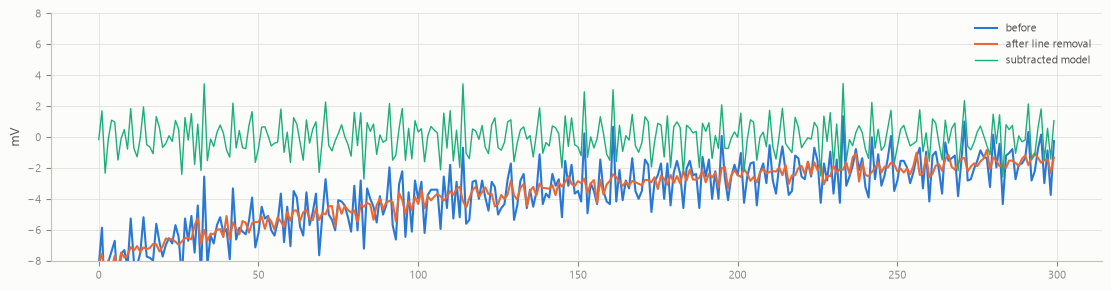

In [22]:
model = interference.subtract_lines(xs, fr_mask, lines, FS, cfgL)
xl = xs - model
print("noise sigma before:", round(signal.noise_sigma(xs) * 1e3, 3), "mV  after:", round(signal.noise_sigma(xl) * 1e3, 3), "mV")
seg = slice(200000, 200300)
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(xs[seg] * 1e3, label="before"); ax[0,0].plot(xl[seg] * 1e3, label="after line removal"); ax[0,0].plot(model[seg] * 1e3, label="subtracted model", linewidth=1)
ax[0,0].set_ylim(-8, 8); ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## C3. `interference.LineRemoval.process(x, free)`
C1 then C2 for one capture; `info` holds the lines and the rms removed.

## C4. `baseline.design_pole_zero(taus, amps)` (from `design_from_template`)

The sampled pulse model is $s[n] = \sum_i a_i\, p_i^{\,n}$ with $p_i = e^{-1/\tau_i}$. Its
z-transform is

$$S(z) = \sum_i \frac{a_i}{1-p_i z^{-1}} = \frac{N(z)}{\prod_i (1-p_i z^{-1})},\qquad
N(z) = \sum_i a_i \prod_{j\ne i}(1-p_j z^{-1})$$

The AC coupling appears twice: as slow **poles** $p_i$ (τ > 30 samples: the undershoot)
and as **zeros of N near z = 1** (they make the net area zero). The correction filter swaps
them:

$$G(z) = \frac{\prod_{\text{slow}}(1-p_i z^{-1})}{\prod_{\text{near 1}}(1-r_k z^{-1})}$$

so $G\cdot S$ has no undershoot. A root at or above 1 would be unstable and is clamped to
$1 - 1/20000$ (a slow leak).

In [23]:
pz = baseline.design_from_template(T)
taus, amps = np.asarray(T.meta["model_taus"]), np.asarray(T.meta["model_amps"])
p = np.exp(-1 / taus)
N = np.zeros(len(p))
for i in range(len(p)):
    q = np.array([1.0])
    for j in range(len(p)):
        if j != i: q = np.convolve(q, [1, -p[j]])
    N = N + amps[i] * q
print("model taus (samples):", np.round(taus, 2), " poles p_i:", np.round(p, 5))
print("roots of N(z):", np.round(np.roots(N), 6))
print("output:", pz.describe())
print("   b =", pz.b, "\n   a =", pz.a)

model taus (samples): [  0.44   7.51  75.94 317.67]  poles p_i: [0.10387 0.87537 0.98692 0.99686]
roots of N(z): [7.40375e+15 1.00018e+00 9.91032e-01]
output: P/Z: cancels tau = [75.9, 317.7] samples, replacement poles tau = [19999.5, 111.0] samples
   b = [ 1.      -1.98377  0.98382] 
   a = [ 1.      -1.99098  0.99098]


## C5. `baseline.PoleZero.process(x)`
Runs the IIR filter $y = G\,x$ (`scipy.signal.lfilter`) and keeps its internal state `zi`
between calls, so a capture processed in chunks gives exactly the same result as in one
piece (streaming-ready). It starts "at rest" on the first sample's level.

chunked == whole: True


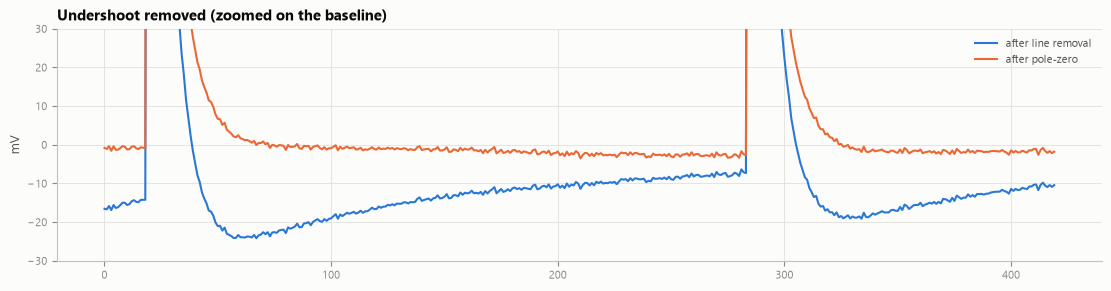

In [24]:
pzs = baseline.PoleZero(pz)
xp = pzs.process(xl)
pz2 = baseline.PoleZero(pz)
chunks = np.concatenate([pz2.process(c) for c in np.array_split(xl, 7)])
print("chunked == whole:", np.allclose(chunks, xp))
p1 = int(pk[30]); seg = slice(p1 - 20, p1 + 400)
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(xl[seg] * 1e3, label="after line removal"); ax[0,0].plot(xp[seg] * 1e3, label="after pole-zero")
ax[0,0].set_ylim(-30, 30); ax[0,0].set_ylabel("mV"); ax[0,0].set_title("Undershoot removed (zoomed on the baseline)"); ax[0,0].legend(); plt.show()

## C6. `baseline.filter_template(template, b, a)`
The detector and the fit must use the pulse shape **as it looks after** pole-zero. The
fine-grid template is evaluated on each of the 16 sub-sample phases, each phase sequence
is filtered at the sample rate, and the results are interleaved back and renormalised.

In [25]:
Tp = baseline.filter_template(T, pz.b, pz.a)
tt = np.array([0., 10, 30, 46, 100, 300])
print("t (samples)        :", tt)
print("template           :", np.round(T(tt), 4))
print("pole-zero template :", np.round(Tp(tt), 4))

t (samples)        : [  0.  10.  30.  46. 100. 300.]
template           : [ 0.9994  0.2376 -0.0287 -0.0431 -0.0273 -0.008 ]
pole-zero template : [ 1.000e+00  2.825e-01  2.180e-02  9.000e-04 -1.000e-03 -8.000e-04]


## C7. `baseline.track_baseline(x, free, cfg)` (inside `BaselineTracker.process`)
A centred moving average of the pulse-free samples (1001 samples; pulses masked 10 before
and 50 after). With cumulative sums of $x\cdot m$ and of $m$:

$$\hat b[i] = \frac{\sum_{j=i-500}^{i+500} x_j m_j}{\sum_{j=i-500}^{i+500} m_j}$$

computed in O(1) per sample. Windows with fewer than 50 free samples are bridged by
interpolation. The estimate is subtracted. Pole-zero boosts slow drift (×13 at 90 Hz), and
this removes it, so the two always go together (ADR-0005).

In [26]:
sp = signal.noise_sigma(xp)
fm = signal.pulse_free_mask(xp.size, signal.find_pulses(xp, sp, 5), 10, 50)
b_est = baseline.track_baseline(xp, fm, baseline.TrackerConfig())
xc = xp - b_est
w = 1500  # warm-up: pole-zero starts without knowing the tails of pulses before the capture
print(f"baseline estimate in the warm-up region (first {w} samples): {b_est[:w].min()*1e3:.1f} to {b_est[:w].max()*1e3:.1f} mV")
print("baseline estimate at samples 1500, 10k, 30k, 100k, 300k (mV):", np.round(b_est[[1500, 10000, 30000, 100000, 300000]] * 1e3, 2))
print("-> pole-zero restores a slowly wandering DC level of a few mV (its low-frequency gain);")
print("   the tracker (1001-sample window) follows it, so the corrected signal stays at zero")
print("median of pulse-free samples before:", round(np.median(xp[w:][fm[w:]]) * 1e3, 3), "mV  after:", round(np.median(xc[w:][fm[w:]]) * 1e3, 3), "mV")

baseline estimate in the warm-up region (first 1500 samples): -3.5 to -3.1 mV
baseline estimate at samples 1500, 10k, 30k, 100k, 300k (mV): [-3.37 -1.52 -1.7  -5.43 -4.98]
-> pole-zero restores a slowly wandering DC level of a few mV (its low-frequency gain);
   the tracker (1001-sample window) follows it, so the corrected signal stays at zero
median of pulse-free samples before: -3.001 mV  after: -0.016 mV


## C8. `preprocess.Preprocessor.process(volts)` (the whole chain)
C0 → C1–C3 → C5 → C7 in one call, with every stage switchable in `PreprocessConfig`.

In [27]:
pre = preprocess.Preprocessor(FS, preprocess.PreprocessConfig(), pz)
y1 = pre.process(volts1)
print("info:", {k: (np.round(v, 5) if np.ndim(v) == 0 else f"{len(v)} lines") for k, v in vars(pre.info).items()})
print("identical to the step-by-step result:", np.allclose(y1, xc))

info: {'offset_v': np.float64(0.00069), 'sigma_in_v': np.float64(0.00142), 'sigma_out_v': np.float64(0.00041), 'line_freqs_hz': '22 lines', 'line_rms_v': np.float64(0.00109)}
identical to the step-by-step result: True


---
# Part D: Detection and events (step 4)

## D1. `detect.kernel_from_template(T, pre=6, post=60)`
The pole-zero template sampled at integer offsets −6…60: the pulse shape **s** used by all filters.

In [28]:
det = detect.Detector(Tp)
print("s =", np.round(det.s, 3), " length", det.s.size)

s = [ 0.     0.     0.     0.002 ... -0.002 -0.002 -0.002 -0.002]  length 67


## D2. `detect.noise_autocovariance(x, free, n_lags)`
The noise covariance from pulse-free samples only (gapped estimator), with $m$ the mask:

$$r[k] = \frac{\sum_i x_i m_i\, x_{i+k} m_{i+k}}{\sum_i m_i m_{i+k}}$$

Both sums are autocorrelations, computed with FFTs (zero-padded to avoid wrap-around) on
the central 131,072 samples.

In [29]:
coarse = signal.find_pulses(y1, signal.noise_sigma(y1), 5)
freeD = signal.pulse_free_mask(y1.size, coarse, 20, 120)
r = detect.noise_autocovariance(y1, freeD, det.s.size)
print("r[0..5] (V²):", r[:6], "   -> correlation", np.round(r[:6] / r[0], 3))

r[0..5] (V²): [3.97344e-07 2.51174e-07 2.57884e-07 2.76586e-07 2.66203e-07 2.42668e-07]    -> correlation [1.    0.632 0.649 0.696 0.67  0.611]


## D3. `detect.optimal_kernel(s, r)`

The best linear amplitude estimator in coloured noise (generalised least squares) is
$\hat A = h^T x / h^T s$ with

$$h = C^{-1}s,\qquad C_{ij} = r[|i-j|]$$

C is Toeplitz, so `scipy.linalg.solve_toeplitz` (Levinson recursion, O(L²)) solves it
directly. Its noise is $\sigma_{\hat A} = (s^T C^{-1} s)^{-1/2}$, the smallest possible.

In [30]:
from scipy.linalg import toeplitz
h = detect.optimal_kernel(det.s, r)
C = toeplitz(r)
s_ = det.s
print("h (normalised) =", np.round(h / np.abs(h).max(), 2))
# noise of A = h.x / h.s is sqrt(h' C h) / (h.s): optimal -> (s' C^-1 s)^-1/2; matched (h = s) -> sqrt(s' C s) / (s.s)
print("theoretical output noise: optimal", round(1e3 / np.sqrt(s_ @ h), 3), "mV;  plain matched",
      round(1e3 * np.sqrt(s_ @ C @ s_) / (s_ @ s_), 3), "mV")

h (normalised) = [-0.28 -0.34 -0.51 -0.63 ... -0.03 -0.06 -0.05 -0.07]
theoretical output noise: optimal 0.256 mV;  plain matched 0.902 mV


## D4. `detect.apply_filter(x, h, s, pre)`

$$y[n] = \frac{\sum_k h[k]\, x[n+k-\text{pre}]}{\sum_k h[k]\, s[k]}$$

If x contains A·s with its peak at n₀, then y[n₀] = A exactly, for **any** kernel h. That
is why the matched filter (h = s) and the optimal filter (h = C⁻¹s) are on the same scale.
Implemented as an FFT correlation.

In [31]:
yo = detect.apply_filter(y1, h, det.s, 6)
ym = detect.apply_filter(y1, det.s, det.s, 6)
q = int(pk[30])
print(f"pulse at {q}: peak sample {y1[q]*1e3:.2f} mV; optimal filter {yo[q]*1e3:.2f} mV; matched filter {ym[q]*1e3:.2f} mV")

pulse at 13788: peak sample 351.15 mV; optimal filter 341.10 mV; matched filter 348.87 mV


## D5. `detect.negative_side_sigma(y)` and `detect.local_sigma(y, 4096)`

Pulses make y positive, so the noise is measured from its negative half: for zero-mean
Gaussian noise $\operatorname{median}(|y|\,:\,y<0) = 0.6745\,\sigma$. `local_sigma` does
this in blocks of 4096 samples and interpolates between block centres, so the threshold
follows interference bursts.

In [32]:
print("negative_side_sigma: optimal", detect.negative_side_sigma(yo) * 1e3, "mV;  matched", detect.negative_side_sigma(ym) * 1e3, "mV")
ls = detect.local_sigma(yo, 4096)
print("local sigma p10/p50/p90 (mV):", np.round(np.percentile(ls, [10, 50, 90]) * 1e3, 3))

negative_side_sigma: optimal 0.37961203000449556 mV;  matched 0.7100033677016406 mV
local sigma p10/p50/p90 (mV): [0.328 0.377 0.473]


## D6. `Detector.response_table(h)`
The filter output produced by a unit pulse whose peak lies p/16 of a sample after a sample
(p = 0…15), over ±66 samples: 16 rows × 133 columns. It is computed directly as one matrix
product of sliding windows with h. Cancellation (D7) subtracts these exact responses.

In [33]:
R = det.response_table(h)
print("shape:", R.shape, "  peak of phase 0:", R[0].max().round(4))
span = R.shape[1] // 2
print("response before the peak (phase 0, offsets -30…-2):", np.round(R[0, span-30:span-1], 3))

shape: (16, 133)   peak of phase 0: 1.0
response before the peak (phase 0, offsets -30…-2): [-0.083 -0.093 -0.085 -0.068 ... -0.081  0.043  0.238  0.518]


## D7. `detect.successive_cancellation(y, R, thr, margin)`

The optimal filter's response has negative dips and small bumps (above), which a plain
peak search would report as extra pulses. Successive cancellation (CLEAN):

1. Take candidates (local maxima above the threshold) in **descending** order (`_cancel_pass`).
2. For each: re-check it in the **residual** output (it may have shrunk when a neighbour
   was subtracted). Accept only if residual ≥ threshold + 3 % × (largest accepted pulse
   whose response overlaps here), it is a local maximum, and it is **not within ±2 samples
   of an accepted pulse** (there, only template mismatch of the real pulse remains).
3. Parabola through the three samples → sub-sample position → phase row p of R.
   $A = y_r[j] / R_p[j-\text{base}]$; subtract $A\,R_p$ from the residual.
4. **Search the residual again** (up to 4 passes): a small pulse hidden under a larger
   pulse's negative dip is not a local maximum of the original output, but it appears once
   the larger pulse has been subtracted.
5. Return the accepted positions, amplitudes and the residual.

Below: a real close pile-up from this capture.

close pair at 8507 8515 (gap 8 samples), amplitudes [ 62.5 265.2] mV


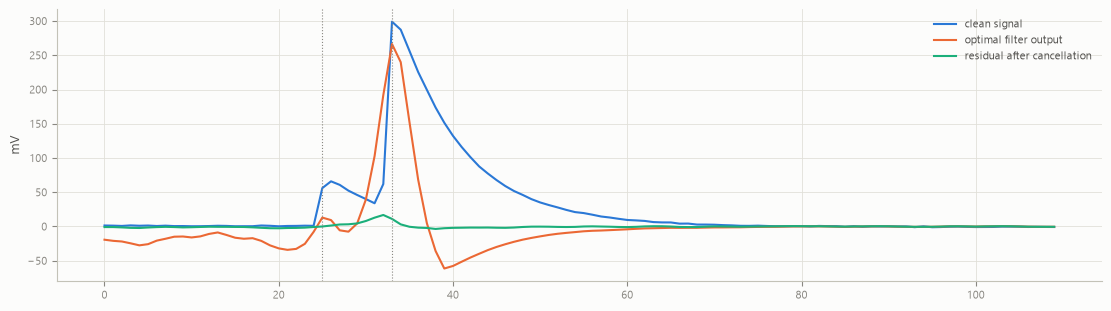

In [34]:
thr, sigma_y = det._threshold(yo)
idxc, ampc, resid = detect.successive_cancellation(yo, R, thr, det.cfg.margin)
gaps = np.diff(idxc); k = int(np.flatnonzero((gaps >= 4) & (gaps <= 12))[0])
a0 = idxc[k] - 25
seg = slice(a0, a0 + 110)
print("close pair at", idxc[k], idxc[k + 1], "(gap", gaps[k], "samples), amplitudes", np.round(ampc[k:k+2] * 1e3, 1), "mV")
fig, ax = P.figure(1, 1, height_per_row=3.0)
t_ = np.arange(110)
ax[0,0].plot(t_, y1[seg] * 1e3, label="clean signal"); ax[0,0].plot(t_, yo[seg] * 1e3, label="optimal filter output")
ax[0,0].plot(t_, resid[seg] * 1e3, label="residual after cancellation")
for j in (k, k + 1): ax[0,0].axvline(idxc[j] - a0, color=P.MUTED, linewidth=0.8, linestyle=":")
ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## D8. `Detector.detect(x)` (two passes)
filter (D2–D4) → threshold from the output (D5) → cancellation (D7) → **re-estimate the
noise from the residual** (real pulses' dips had inflated it) → cancellation again with the
lower threshold.

In [35]:
d1 = det.detect(y1)
print(f"output: {d1.index.size} pulses; filter noise {d1.sigma*1e3:.3f} mV (first pass {sigma_y*1e3:.3f}); median threshold {d1.threshold_v*1e3:.2f} mV")
print("first indices:", d1.index[:8], " amplitudes (mV):", np.round(d1.filter_amplitude[:8] * 1e3, 1))

output: 1314 pulses; filter noise 0.271 mV (first pass 0.380); median threshold 1.49 mV
first indices: [ 454  966 1398 2102 2155 2292 2633 3700]  amplitudes (mV): [252.4 152.5  82.  319.  161.5 179.2 225.7 251.4]


## D9. Alternatives: `detect.sharpen(x, tau)` and `decay_constant(T)`
`decay_constant` fits log s(t) over 4…25 samples (τ ≈ 7.7). `sharpen` computes
$x[n] - a\,x[n-1]$ with $a=e^{-1/\tau}$: an exponential decay becomes 0, so each pulse
collapses onto its rising edge (method `"sharpened"`).

In [36]:
print("decay constant:", detect.decay_constant(Tp))
print("sharpened template around the peak:", np.round(detect.sharpen(Tp(np.arange(-3, 8.)), detect.decay_constant(Tp)), 3))

decay constant: 7.687663946178681
sharpened template around the peak: [ 0.002 -0.001  0.385  0.662  0.061  0.01  -0.001 -0.003 -0.004 -0.003 -0.003]


## D10. `pipeline.Pipeline.process_capture(volts, capture, t0)`

For one capture: pre-process (C8) → detect (D8) → then

* **gaps** to the neighbours; **clusters**: a new cluster starts when the gap ≥ 60 samples
  (a template fit window is −10…+40, so closer pulses share one);
* **flags**: PILEUP (cluster > 1), WARMUP (first 1500 samples), EDGE, then the template fit
  (B7, baseline fixed at 0) of isolated pulses → amplitude, shift, rms; BAD_FIT if
  rms > 4σ + 2 % × A; LARGE (> 1.5 V) and AFTER_LARGE (200 samples after one);
* **snippets**: clean waveform of each pile-up cluster (−20…+80 samples), kept for re-analysis;
* **pile-up solver** (`_solve_clusters`, explained in E9–E10): amplitudes and sub-sample
  times for every pulse in a cluster (and for badly fitted isolated pulses), plus pulses
  found by its residual search (flag FIT_ADDED); gaps and cluster sizes recomputed;
* **time** = capture time + (index + shift) × Δt.

In [37]:
pipe = pipeline.Pipeline(T, FS)
with store.CaptureStore(SRC_STORE) as s:
    ev, row, sn = pipe.process_capture(s.volts(1), 1, float(s.time_s[1]))
names = ["index", "amplitude", "filter_amplitude", "shift", "fit_rms", "flags", "cluster", "cluster_size", "gap_prev"]
print(" ".join(f"{n:>16s}" for n in names))
for e in ev[5:15]:
    print(" ".join(f"{e[n]:16.5g}" for n in names))
print("\ncapture row:", row[0])
print("snippets:", len(sn), "; first:", sn[0][0], "capture", sn[0][1], "start", sn[0][2], "length", sn[0][3].size)

           index        amplitude filter_amplitude            shift          fit_rms            flags          cluster     cluster_size         gap_prev
            2292          0.18417          0.17915          0.55535        0.0011918                0                4                1              137
            2633          0.22558          0.22566        -0.029068       0.00085698                0                5                1              341
            3700          0.24955          0.25139        -0.092292       0.00068217                0                6                1             1067
            4810           0.0878         0.086172          0.63046       0.00042949                0                7                1             1110
            5063          0.36592          0.37061         -0.32934          0.00108                0                8                1              253
            5409         0.096401         0.095608          0.58116       0.000717

## D11. `pipeline.run(...)`, `events.EventWriter`, `events.EventFile`, `summarize`

`run` processes all captures (in parallel worker processes, `_worker_run`), makes cluster
ids unique, and appends each capture's rows with `EventWriter.append` to resizable,
compressed column datasets. `EventFile` reads everything back (`events`, `captures`,
`snippet(cluster)`, `clean()`, `live_time_s`). `summarize` reports rates and flags.

In [38]:
r = pipeline.run(SRC_STORE, TEMPLATE, TMP / "ev.h5", limit=5, workers=1, verbose=False)
print("run:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()})
ef = events.EventFile(TMP / "ev.h5")
print("events:", ef.events.size, " live time:", round(ef.live_time_s, 3), "s  clean:", ef.clean().size, " snippets:", ef.n_snippets)
cap, start, w = ef.snippet(int(ef.events[(ef.events["flags"] & events.FLAG_PILEUP) != 0]["cluster"][0]))
print("a snippet:", cap, start, w.shape)
print(json.dumps(pipeline.summarize(TMP / "ev.h5"), indent=1)[:600])

run: {'captures': 5, 'events': 6619, 'elapsed_s': 3.88, 'samples_per_s': 674883.59, 'file_bytes': 689894, 'text_bytes': 36700160}
events: 6619  live time: 1.452 s  clean: 4828  snippets: 768
a snippet: 0 508 (179,)
{
 "events": 6619,
 "live_time_s": 1.4520749999999998,
 "rate_cps": 4544.5311020436275,
 "clean": 4828,
 "snippets": 768,
 "flag_fractions_of_valid": {
  "pileup": 0.2620093953629338,
  "warmup": 0.0,
  "edge": 0.0,
  "bad_fit": 0.02621609334747689,
  "large": 0.0015153811183512653,
  "after_large": 0.002273071677526898,
  "fit_added": 0.0033338384603727837
 },
 "median_filter_sigma_mv": 0.2772504687309265,
 "median_threshold_mv": 1.529123067855835
}


## D12. `spectrum.fit_peaks(values, centers, lo, hi, bin_width)`
Histogram, then fit N Gaussians on a linear background by weighted least squares
(`curve_fit`, Poisson weights $1/\sqrt{\max(n,1)}$). Resolution = FWHM / centre with
FWHM = 2√(2 ln 2) σ = 2.355 σ. Here: the ⁶⁰Co lines from the full 100-capture event file.

centres (V): [0.3157 0.3573]  FWHM: [6.47 5.86] %  ± [0.08 0.07]
ratio of centres: 1.1317 (1332/1173 = 1.1355)


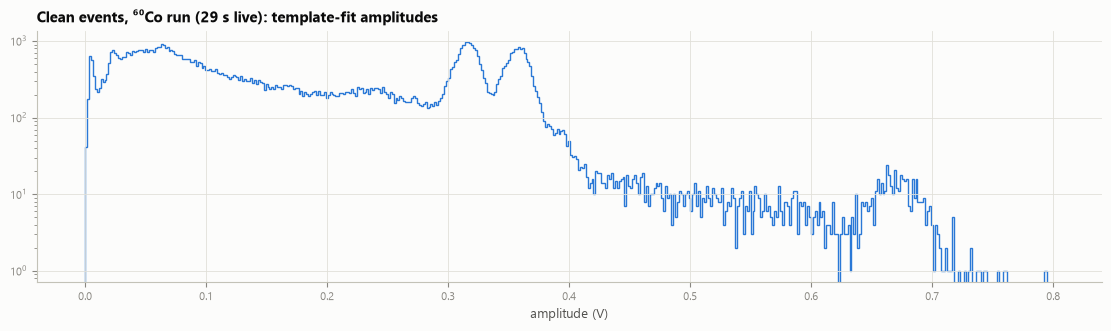

In [39]:
efull = events.EventFile(ROOT / "data/events/source_first100.h5")
amp = efull.clean()["amplitude"]
pf = spectrum.fit_peaks(amp, [0.316, 0.357], 0.27, 0.40, 0.002)
print("centres (V):", np.round(pf.centers, 4), " FWHM:", np.round(100 * pf.resolution, 2), "%  ±", np.round(100 * pf.resolution_err, 2))
print("ratio of centres:", round(pf.centers[1] / pf.centers[0], 4), "(1332/1173 = 1.1355)")
edges = np.linspace(0, 0.8, 500)
fig, ax = P.figure(1, 1, height_per_row=3.2)
ax[0,0].stairs(np.histogram(amp, edges)[0], edges); ax[0,0].set_yscale("log"); ax[0,0].set_xlabel("amplitude (V)")
ax[0,0].set_title("Clean events, ⁶⁰Co run (29 s live): template-fit amplitudes"); plt.show()

---
# Part E: Pile-up resolution (step 5)

A pile-up cluster is a stretch of clean signal with two or more pulses closer than 60
samples. Every method in `gammaspec.pileup` takes the cluster waveform **y** (baseline 0),
the detected peak positions **pos** (relative to the start of y) and a `PileupContext`, and
returns one amplitude per pulse. We use a real ⁶⁰Co pile-up cluster from the event file.

## E0. A real cluster: `EventFile.snippet(cluster)`

cluster 1305: capture 1, snippet starts at sample 75753, length 108
positions in the snippet: [20. 28.]  detector amplitudes (mV): [314.3  21.5]


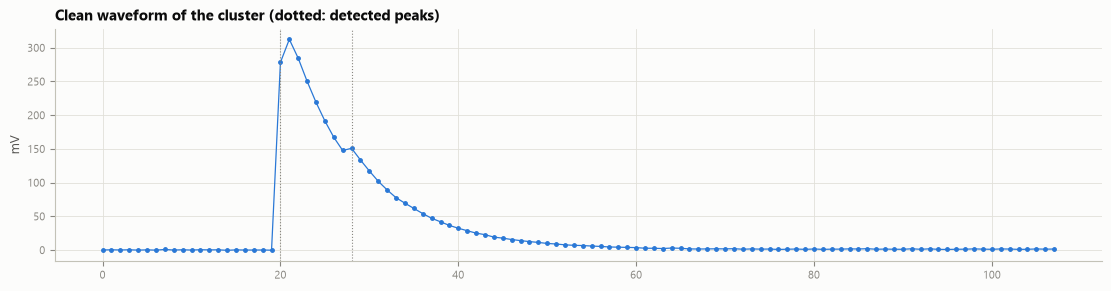

In [40]:
ev_all = efull.events
ok_flags = (ev_all["flags"] & (events.FLAG_WARMUP | events.FLAG_EDGE)) == 0
cand = ev_all[(ev_all["cluster_size"] == 2) & (ev_all["gap_next"] >= 6) & (ev_all["gap_next"] <= 10)
              & (ev_all["filter_amplitude"] > 0.25) & ok_flags]
cl = int(cand["cluster"][0])
cap, start, yc = efull.snippet(cl)
rows = ev_all[ev_all["cluster"] == cl]
pos = (rows["index"] - start).astype(float)
print(f"cluster {cl}: capture {cap}, snippet starts at sample {start}, length {yc.size}")
print("positions in the snippet:", pos, " detector amplitudes (mV):", np.round(rows["filter_amplitude"] * 1e3, 1))
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(yc * 1e3, marker="o", markersize=2.5, linewidth=0.9)
for p_ in pos: ax[0,0].axvline(p_, color=P.MUTED, linestyle=":", linewidth=0.8)
ax[0,0].set_ylabel("mV"); ax[0,0].set_title("Clean waveform of the cluster (dotted: detected peaks)"); plt.show()

## E1. `pileup.PileupContext`
Holds what the methods need: the (pole-zero-corrected) template **s**, its decay constant
τ (for HYPER), the noise autocovariance (for GLS/WLS), the template mismatch ε (for WLS),
and the timing-refinement settings. `derivative(t)` is the central difference
$s'(t) \approx [s(t+h) - s(t-h)]/2h$ with h = 1/16 sample. The noise autocovariance here is
measured from capture 1's pulse-free samples (as in D2), now with 4096 lags.

In [41]:
from gammaspec import pileup
r_long = detect.noise_autocovariance(y1, freeD, 4096)
ctx = pileup.PileupContext(Tp, detect.decay_constant(Tp), r_long)
print("tau =", round(ctx.tau, 3), " model_error eps =", ctx.model_error, " noise variance r[0] =", r_long[0])
print("s(t) and s'(t) at t = -1, 0, 1, 5:", np.round(Tp(np.array([-1., 0, 1, 5])), 3), np.round(ctx.derivative(np.array([-1., 0, 1, 5])), 3))

tau = 7.688  model_error eps = 0.0035  noise variance r[0] = 3.9734448329256136e-07
s(t) and s'(t) at t = -1, 0, 1, 5: [0.385 1.    0.939 0.558] [ 1.692 -0.003 -0.113 -0.096]


## E2. `pileup.tm(y, pos, ctx)`: template matching (the paper)

Measured amplitude of pulse p = the sample at its peak, $b_p = y[t_p]$. Each $b_p$ is the
pulse's own amplitude plus the tails of the **earlier** pulses at that point:

$$b_p = \sum_{q \le p} M_{pq}\, a_q,\qquad M_{pq} = s(t_p - t_q),\quad M_{pp} = s(0) = 1$$

M is lower triangular with a unit diagonal, so a is found by forward substitution
(`solve_triangular`). It uses **one sample per pulse**, and assumes the peak is exactly on
a sample.

In [42]:
b_meas = yc[np.round(pos).astype(int)]
dd = pos[:, None] - pos[None, :]
M = np.where(dd >= 0, Tp(dd), 0.0)
print("b =", np.round(b_meas * 1e3, 2), "mV\nM =\n", np.round(M, 4))
print("a = M^-1 b =", np.round(pileup.tm(yc, pos, ctx) * 1e3, 2), "mV")

b = [278.35 150.87] mV
M =
 [[1.     0.    ]
 [0.3705 1.    ]]
a = M^-1 b = [278.35  47.73] mV


## E3. `pileup.hyper(y, pos, ctx)`: HYPER

For mono-exponential pulses $A_q e^{-\lambda(t-t_q)}$, between pulse p and p+1:

$$D(t) = y(t) + \lambda\int_{t_p}^{t} y\,dt' = \sum_{q\le p} A_q e^{-\lambda(t_p - t_q)} = \text{const} = D_p$$

(differentiate: $\dot y = -\lambda y$ between pulses, so $\dot D = 0$). Hence
$D_p = A_p + D_{p-1}e^{-\lambda(t_p - t_{p-1})}$ and

$$A_p = D_p - D_{p-1}\,e^{-\lambda (t_p - t_{p-1})}$$

D_p is averaged over the segment (trapezoidal integral, from the peak, at most 3τ long).
Our pulses are not purely exponential (finite rise), which biases HYPER.

In [43]:
lam = 1 / ctx.tau
p_ = np.round(pos).astype(int)
for k in range(p_.size):
    a_, b_ = p_[k], min(p_[k + 1] if k + 1 < p_.size else yc.size, p_[k] + int(3 * ctx.tau))
    seg_ = yc[a_:b_]; integ = np.concatenate([[0.0], np.cumsum(0.5 * (seg_[1:] + seg_[:-1]))])
    Dt = seg_ + lam * integ
    print(f"segment {k}: D(t) first values {np.round(Dt[:6] * 1e3, 1)} mV -> mean D_{k} = {Dt.mean() * 1e3:.2f} mV")
print("HYPER amplitudes:", np.round(pileup.hyper(yc, pos, ctx) * 1e3, 2), "mV")

segment 0: D(t) first values [278.4 350.9 361.7 362.3 361.7 360.7] mV -> mean D_0 = 349.54 mV
segment 1: D(t) first values [150.9 152.1 152.1 151.1 150.7 150. ] mV -> mean D_1 = 152.40 mV
HYPER amplitudes: [349.54  28.93] mV


## E4. `pileup.ls(y, pos, ctx)`: least squares with integer times

Model the **whole** cluster: $y(t) = \sum_k A_k\, s(t - t_k) + \text{noise}$. With the
design matrix $S_{tk} = s(t - t_k)$ (one column per pulse) this is linear:

$$\hat A = \arg\min \lVert y - S A\rVert^2 = (S^TS)^{-1}S^Ty$$

(`np.linalg.lstsq`). It uses all samples, so it averages noise, but it still assumes the
peaks are on samples.

In [44]:
t_ = np.arange(yc.size, dtype=float)
S = Tp(t_[:, None] - pos[None, :])
print("design matrix S:", S.shape, "  S^T S =\n", np.round(S.T @ S, 3))
print("LS amplitudes:", np.round(pileup.ls(yc, pos, ctx) * 1e3, 2), "mV")

design matrix S: (108, 2)   S^T S =
 [[4.992 1.854]
 [1.854 4.992]]
LS amplitudes: [312.96  35.  ] mV


## E5. `pileup.ls_refine`: least squares with sub-sample timing (`_ls(refine=True)`)

The arrival times are refined jointly with the amplitudes (Gauss–Newton). For a small
time shift δ:

$$A\,s(t - t_k - \delta) \approx A\,s(t - t_k) - (A\delta)\, s'(t - t_k)$$

which is still linear, now in $A_k$ and $(A\delta)_k$: solve
$y \approx [\,S \;\; -S'\,]\,[A;\; A\delta]$, take $\delta_k = (A\delta)_k / A_k$
(at most ±0.5 per step, ±0.75 in total), update $t_k$, repeat 4 times, then solve for A at
the final times. Below, one step by hand, then the function.

In [45]:
Dmat = ctx.derivative(t_[:, None] - pos[None, :])
coef, *_ = np.linalg.lstsq(np.hstack([S, -Dmat]), yc, rcond=None)
A1, Ad1 = coef[:2], coef[2:]
print("one Gauss-Newton step: A =", np.round(A1 * 1e3, 2), "mV, delta =", np.round(Ad1 / A1, 3), "samples")
A_ref, t_ref = pileup._ls(yc, pos, ctx, refine=True, whiten=False)
print("ls_refine: A =", np.round(A_ref * 1e3, 2), "mV at times", np.round(t_ref, 3), "(detected:", pos, ")")

one Gauss-Newton step: A = [316.65  29.84] mV, delta = [0.233 0.059] samples
ls_refine: A = [322.23  24.33] mV at times [20.525 28.178] (detected: [20. 28.] )


## E6. `pileup.gls_refine`: whitened least squares (`_whitener`)

With noise covariance C (Toeplitz from the autocovariance), the maximum-likelihood estimate
minimises $(y - SA)^T C^{-1} (y - SA)$. With the Cholesky factor $C = LL^T$, multiply
everything by $L^{-1}$ (`solve_triangular`): the noise becomes white and ordinary least
squares applies to $L^{-1}y$ and $L^{-1}S$ ("prewhitening"). The timing refinement is the
same as E5.

In [46]:
from scipy.linalg import solve_triangular
Lc = pileup._whitener(ctx, yc.size)
print("Cholesky factor:", Lc.shape, " L[0:3,0:3] =\n", np.round(Lc[:3, :3] * 1e3, 4), "(mV)")
# whitening real noise: take pulse-free stretches of capture 1 as long as the cluster
wins_, _ = noise.pulse_free_windows(y1, freeD, yc.size)
z = np.array([solve_triangular(Lc, w_, lower=True) for w_ in wins_])
print(f"{len(wins_)} real noise windows: before whitening std {wins_.std()*1e3:.3f} mV, lag-1 correlation {np.corrcoef(wins_[:, :-1].ravel(), wins_[:, 1:].ravel())[0,1]:.3f}")
print(f"after L^-1: std {z.std():.3f} (should be 1), lag-1 correlation {np.corrcoef(z[:, :-1].ravel(), z[:, 1:].ravel())[0,1]:.3f} (should be 0)")
print("gls_refine: A =", np.round(pileup.gls_refine(yc, pos, ctx) * 1e3, 2), "mV")

Cholesky factor: (108, 108)  L[0:3,0:3] =
 [[0.6304 0.     0.    ]
 [0.3985 0.4884 0.    ]
 [0.4091 0.1805 0.4443]] (mV)


3042 real noise windows: before whitening std 0.646 mV, lag-1 correlation 0.639
after L^-1: std 1.013 (should be 1), lag-1 correlation -0.017 (should be 0)
gls_refine: A = [321.88  23.23] mV


## E7. `pileup.wls_refine`: noise + template-mismatch weighting (the chosen method)

GLS assumes the template is exact. Real pulses differ from it by a small, amplitude-
proportional amount. The fit residuals of the isolated pulses show it:

$$\text{rms}^2 = \sigma_0^2 + (\varepsilon A)^2$$

`wls_refine` adds that model error to the covariance:
$C = C_\text{noise} + (\varepsilon\, A_\max)^2 I$, with $A_\max$ from a first unweighted fit.
Small pulses (noise-dominated) are weighted like GLS; large pulses (mismatch-dominated) like
ordinary LS. Below, ε is measured from the clean events of the event file.

In [47]:
cl_ev = efull.clean(); a_ = cl_ev["amplitude"]; r_ = cl_ev["fit_rms"]
m_ = (a_ > 0.005) & (a_ < 0.6)
c0, c1 = np.linalg.lstsq(np.vstack([np.ones(m_.sum()), a_[m_] ** 2]).T, r_[m_] ** 2, rcond=None)[0]
print(f"fit of rms^2 = sigma0^2 + (eps A)^2 over {m_.sum()} clean events: sigma0 = {np.sqrt(c0)*1e3:.3f} mV, eps = {np.sqrt(c1)*100:.3f} %")
A0 = pileup.ls(yc, pos, ctx)
print(f"extra variance for this cluster: (eps * A_max)^2 = ({ctx.model_error} * {A0.max()*1e3:.1f} mV)^2 = {(ctx.model_error*A0.max()*1e3)**2:.3f} mV^2  vs noise r[0] = {r_long[0]*1e6:.3f} mV^2")
print("wls_refine: A =", np.round(pileup.wls_refine(yc, pos, ctx) * 1e3, 2), "mV")

fit of rms^2 = sigma0^2 + (eps A)^2 over 95267 clean events: sigma0 = 0.673 mV, eps = 0.351 %
extra variance for this cluster: (eps * A_max)^2 = (0.0035 * 313.0 mV)^2 = 1.200 mV^2  vs noise r[0] = 0.397 mV^2
wls_refine: A = [321.69  23.3 ] mV


## E8. `pileup.resolve(method, y, pos, ctx)`: all methods on this cluster
`resolve` dispatches by name. Below: every method's amplitudes, and the WLS fit with its
residual.

tm          [278.35  47.73] mV
hyper       [349.54  28.93] mV
ls          [312.96  35.  ] mV
ls_refine   [322.23  24.33] mV
gls_refine  [321.88  23.23] mV
wls_refine  [321.69  23.3 ] mV


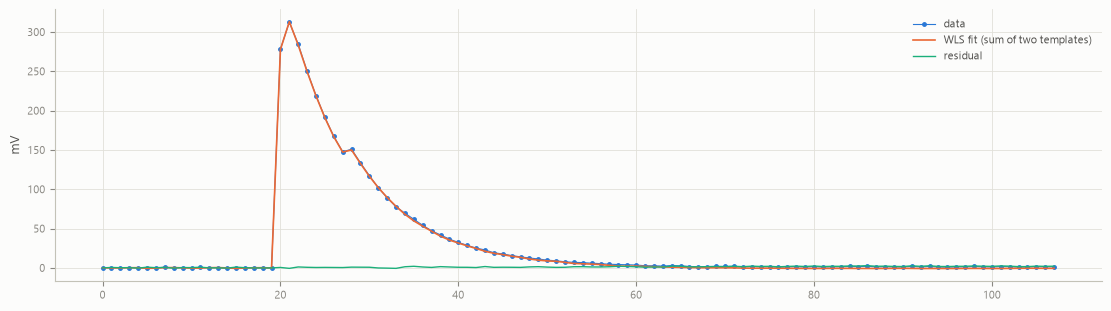

In [48]:
for m in pileup.METHODS:
    print(f"{m:11s}", np.round(pileup.resolve(m, yc, pos, ctx) * 1e3, 2), "mV")
A_w, t_w = pileup._ls(yc, pos, ctx, refine=True, whiten=True,
                      extra_var=(ctx.model_error * pileup.ls(yc, pos, ctx).max()) ** 2)
model_w = Tp(t_[:, None] - t_w[None, :]) @ A_w
fig, ax = P.figure(1, 1, height_per_row=3.0)
ax[0,0].plot(t_, yc * 1e3, marker="o", markersize=2.5, linewidth=0.8, label="data")
ax[0,0].plot(t_, model_w * 1e3, linewidth=1.2, label="WLS fit (sum of two templates)")
ax[0,0].plot(t_, (yc - model_w) * 1e3, linewidth=1.0, label="residual")
ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## E9. `solver.PileupSolver` (step 6): the chosen method inside the pipeline

`PileupSolver(template, noise_acov, SolverConfig)` is built once per capture.

* `taper_autocovariance(acov, 512)`: keeps 512 lags and tapers the last quarter smoothly
  to 0 (half-cosine). An abruptly truncated autocovariance can make the Toeplitz matrix
  indefinite, and then the Cholesky factorisation fails.
* `_whitener(n, extra_var)`: C = Toeplitz(r) + extra_var·I → Cholesky L → **W = L⁻¹**,
  formed once per cluster, so every later whitening is a single matrix product.
* `_fit(y, t0, W, Wy)`: the WLS + timing fit of E5–E7, solving the small normal equations
  $(X_w^T X_w)\,c = X_w^T y_w$ each iteration and stopping when no time moves by more
  than 0.005 samples (times stay within ±1.25 samples of the detected positions).
  `PulseTemplate.derivative(t)` gives s'(t) from a precomputed central-difference array,
  and `PulseTemplate.__call__` interpolates by direct indexing on its uniform grid.
* `solve(y, positions)`: (1) unweighted LS to get $A_\max$ for the mismatch term;
  (2) whitening matrix; (3) fit; (4) **residual search**: for candidate times τ every half
  sample, with whitened residual $r_w$ and whitened template $s_w(\tau)$,

  $$A^*(\tau) = \frac{s_w\cdot r_w}{s_w\cdot s_w},\qquad z(\tau) = \frac{s_w\cdot r_w}{\sqrt{s_w\cdot s_w}}$$

  ($z^2$ is the drop in $\chi^2$ from adding that pulse). If max z > 8, positive, at least
  one sample from the existing pulses: add it, refit everything, and keep it only if its
  amplitude is still > 8σ. (5) rms and whitened χ² per sample.

Below: a real cluster where the detector saw **one** pulse but the solver found two.

detected positions: [10] -> solver times: [10.09  8.3 ] amplitudes (mV): [320.9 137.4] added: [False  True]
rms 1.388 mV, whitened chi2 per sample 0.23
without the search: one pulse of 422.2 mV, rms 19.234 mV, chi2 121.3


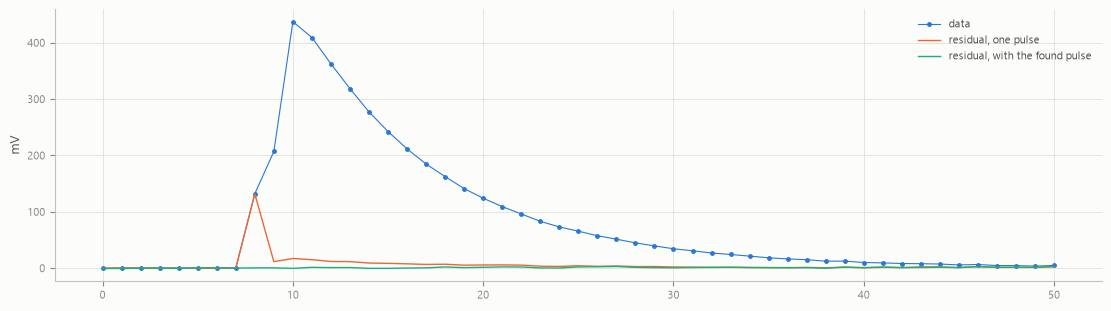

In [49]:
from gammaspec import solver
ev_s = efull.events
added_ev = ev_s[(ev_s["flags"] & events.FLAG_FIT_ADDED) != 0]
pick = added_ev[(added_ev["amplitude"] > 0.03)][0]
cap_s, cl_s = int(pick["capture"]), int(pick["cluster"])
rows_s = ev_s[ev_s["cluster"] == cl_s]
detected_rows = rows_s[(rows_s["flags"] & events.FLAG_FIT_ADDED) == 0]
pipe_s = pipeline.Pipeline(T, FS)
with store.CaptureStore(SRC_STORE) as s:
    pipe_s.pre.reset(); ys = pipe_s.pre.process(s.volts(cap_s))
a_s = int(detected_rows["index"][0]) - 10
b_s = int(detected_rows["index"][-1]) + 41
free_s = signal.pulse_free_mask(ys.size, pipe_s.detector.detect(ys).index, 20, 120)
sv = solver.PileupSolver(Tp, detect.noise_autocovariance(ys, free_s, 512), solver.SolverConfig())
res_s = sv.solve(ys[a_s:b_s], detected_rows["index"] - a_s)
print("detected positions:", detected_rows["index"] - a_s, "-> solver times:", np.round(res_s.time, 2),
      "amplitudes (mV):", np.round(res_s.amplitude * 1e3, 1), "added:", res_s.added)
print(f"rms {res_s.rms*1e3:.3f} mV, whitened chi2 per sample {res_s.chi2:.2f}")
no_search = solver.PileupSolver(Tp, detect.noise_autocovariance(ys, free_s, 512), solver.SolverConfig(residual_search=False))
r1 = no_search.solve(ys[a_s:b_s], detected_rows["index"] - a_s)
tt_s = np.arange(b_s - a_s, dtype=float)
m1 = Tp(tt_s[:, None] - r1.time[None, :]) @ r1.amplitude
m2 = Tp(tt_s[:, None] - res_s.time[None, :]) @ res_s.amplitude
print(f"without the search: one pulse of {r1.amplitude[0]*1e3:.1f} mV, rms {r1.rms*1e3:.3f} mV, chi2 {r1.chi2:.1f}")
fig, ax = P.figure(1, 1, height_per_row=3.0)
ax[0,0].plot(tt_s, ys[a_s:b_s] * 1e3, marker="o", markersize=2.5, linewidth=0.8, label="data")
ax[0,0].plot(tt_s, (ys[a_s:b_s] - m1) * 1e3, linewidth=1.0, label="residual, one pulse")
ax[0,0].plot(tt_s, (ys[a_s:b_s] - m2) * 1e3, linewidth=1.0, label="residual, with the found pulse")
ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## E10. `Pipeline._solve_clusters`, `EventFile.good()` and `pipeline.spectrum_report`

* `_solve_clusters(e, y, detected)`: noise autocovariance of the capture (pulse-free mask
  around the detections); for each cluster of > 1 pulse, and each isolated pulse flagged
  BAD_FIT, `solve` the window [first − 10, last + 40]; write amplitudes, shifts
  (= solver time − index) and rms; set or clear BAD_FIT (rms > 4σ + 2 % A_max); append
  found pulses as new rows (PILEUP | FIT_ADDED); sort; recompute gaps and cluster sizes.
* `EventFile.good(include_pileup=True)`: every event with a finite amplitude whose flags are
  only PILEUP / FIT_ADDED (how it was measured), i.e. no warm-up, edge, bad fit or large
  pulse. `clean()` stays "no flags at all" (isolated pulses).
* `spectrum_report(events)`: Gaussian peak fits (`fit_peaks`, D12) of isolated, resolved
  pile-up (by gap) and all good events, with shifts relative to isolated and the
  throughput (good / valid events). Categories with < 1000 events in the peak region are
  not fitted.

In [50]:
rep = pipeline.spectrum_report(ROOT / "data/events/source_first100.h5")
print(f"throughput {100*rep['throughput']:.1f} % (isolated only {100*rep['isolated_fraction']:.1f} %), pulses found by the solver: {rep['fit_added']}")
for name, c in rep["categories"].items():
    if "error" in c:
        print(f"  {name:46s} n={c['n']:6d}  not fitted ({c['error']})")
    else:
        print(f"  {name:46s} n={c['n']:6d}  FWHM {' / '.join(f'{x:.2f}' for x in c['fwhm_pct'])} %   shift {' / '.join(f'{x:+.2f}' for x in c['shift_pct'])} %")

throughput 97.3 % (isolated only 73.0 %), pulses found by the solver: 595
  isolated                                       n= 96827  FWHM 6.47 / 5.84 %   shift +0.00 / +0.00 %
  pile-up (all)                                  n= 32143  FWHM 6.45 / 5.94 %   shift -0.05 / -0.08 %
  pile-up, gap < 3 (incl. found by the solver)   n=   523  not fitted (too few events in the peak region (116))
  pile-up, gap 3-10                              n=  5641  FWHM 7.54 / 5.61 %   shift +0.04 / -0.02 %
  pile-up, gap 10-30                             n= 11072  FWHM 6.22 / 6.33 %   shift +0.08 / -0.11 %
  pile-up, gap 30-60                             n= 14907  FWHM 6.34 / 5.75 %   shift -0.18 / -0.09 %
  all good events                                n=128970  FWHM 6.47 / 5.86 %   shift -0.01 / -0.02 %


---
# Part G: Energy calibration and background subtraction (step 7)

Input: the good events of the source run and of the background run (event files from
`gammaspec process`). Output: both on a keV axis, live-time-normalised spectra, and the
net spectrum.

## G1. `calibration.anchor_gain(amplitudes, kind)`
A first gain (keV per volt) from an unmistakable line. `_peaks_in` histograms the
amplitudes, smooths them, and returns the most prominent peaks.
* **source:** the pair of peaks whose centre ratio is closest to 1332.5 / 1173.2 = 1.1357
  (within 2 %) is ⁶⁰Co: gain = mean(1173.2 / A₁, 1332.5 / A₂);
* **background:** the strongest peak is ⁴⁰K: gain = 1460.8 / A.

In [51]:
from gammaspec import calibration, analysis
src_good = efull.good()
bkg_good = events.EventFile(ROOT / "data/events/background.h5").good()
g_src = calibration.anchor_gain(src_good["amplitude"], "source")
g_bkg = calibration.anchor_gain(bkg_good["amplitude"], "background")
print(f"source anchor gain {g_src:.1f} keV/V  ->  1173.2 keV predicted at {1173.228/g_src:.4f} V")
print(f"background anchor gain {g_bkg:.1f} keV/V ->  1460.8 keV predicted at {1460.82/g_bkg:.4f} V")

source anchor gain 3717.5 keV/V  ->  1173.2 keV predicted at 0.3156 V
background anchor gain 3968.6 keV/V ->  1460.8 keV predicted at 0.3681 V


## G2. `calibration.fit_lines(amplitudes, lines, gain)` → `_fit_group`

Each library line is predicted at A = E / gain. Lines within 16 % of each other form a
group and are fitted together by `spectrum.fit_peaks` with **bounds**: centre ±4 %, width
0.5–2× the expected NaI resolution
$\sigma(E) = E \cdot \tfrac{0.065}{2.3548}\sqrt{1173/E}$ (`expected_sigma_rel`), area ≥ 0.
A line is accepted if its area is ≥ 4σ, its centre and width are not at a bound, and its
FWHM is 2.5–15 %. If one is rejected, the least significant rejected line is dropped and
the rest of the group refitted, until all remaining lines are accepted.

In [52]:
pts = calibration.fit_lines(src_good["amplitude"], calibration.SOURCE_LINES, g_src)
for p_ in pts:
    print(f"{p_.label:10s} {p_.energy_kev:8.1f} keV  A = {p_.amplitude_v:.4f} V  FWHM {p_.fwhm_pct:5.2f} %  area {p_.area:7.0f}  "
          + ("accepted" if p_.accepted else "rejected: " + p_.note))

Co-60        1173.2 keV  A = 0.3157 V  FWHM  6.48 %  area   14826  accepted
Co-60        1332.5 keV  A = 0.3572 V  FWHM  5.88 %  area   13190  accepted
K-40         1460.8 keV  A = 0.3923 V  FWHM  2.92 %  area     248  rejected: width pinned at its bound (FWHM 2.9 %): not a measured peak
Co-60 sum    2505.7 keV  A = 0.6703 V  FWHM  5.57 %  area     461  accepted
Tl-208       2614.5 keV  A = 0.6893 V  FWHM  2.22 %  area      46  rejected: FWHM 2.2 % outside (2.5, 15.0)


## G3. `calibration.fit_calibration(points)`

Weighted least squares of $E = \sum_i c_i A^i$ through the accepted points. The weight of a
point is $1/\sigma_E$ with $\sigma_E^2 = (\sigma_A \cdot \text{gain})^2 + (0.001\,E)^2$ (centre
uncertainty plus a 0.1 % systematic). Linear by default; quadratic only with ≥ 4 points and
if it halves χ²/ndf. With exactly two points the line passes through them, and a weak pin
at (0, 0) keeps the offset reasonable.

In [53]:
cal_src = calibration.fit_calibration(pts)
print("coefficients (keV, keV/V):", np.round(cal_src.coeffs, 3), "  chi2/ndf", round(cal_src.chi2_ndf, 2))
for lab, e_, r_ in cal_src.residuals_kev():
    print(f"  residual {lab:10s} {e_:8.1f} keV: {r_:+.2f} keV")

coefficients (keV, keV/V): [ -12.511 3760.21 ]   chi2/ndf 2.94
  residual Co-60        1173.2 keV: +1.24 keV
  residual Co-60        1332.5 keV: -1.79 keV
  residual Co-60 sum    2505.7 keV: +2.44 keV


## G4. `calibration.gain_match(points, reference)`

The background run has only ⁴⁰K. Same detector and electronics, so the calibration
*shape* (offset, curvature) is taken from the source run, with one gain factor k:

$$E_{bkg}(A) = E_{ref}(k A) = \sum_i c_i k^i A^i$$

k is found for each accepted line by solving $E_{ref}(k A_\text{line}) = E_\text{line}$
(Brent's method), and averaged with weights $(A/\sigma_A)^2$.

In [54]:
pts_b = calibration.fit_lines(bkg_good["amplitude"], calibration.BACKGROUND_LINES, g_bkg)
print("accepted background lines:", [(p_.label, p_.energy_kev) for p_ in pts_b if p_.accepted])
cal_bkg = calibration.gain_match(pts_b, cal_src)
k_ = cal_bkg.coeffs[1] / cal_src.coeffs[1]
print(f"k = {k_:.4f}: the background run's gain is {100*(1-1/k_):.1f} % lower;  E_bkg(A) = {cal_bkg.coeffs[0]:.2f} + {cal_bkg.coeffs[1]:.2f} A")
print(f"without gain matching, the background 40K would appear at {cal_src.energy(pts_b[[p_.label for p_ in pts_b].index('K-40')].amplitude_v):.0f} keV")

accepted background lines: [('K-40', 1460.82)]
k = 1.0754: the background run's gain is 7.0 % lower;  E_bkg(A) = -12.51 + 4043.85 A
without gain matching, the background 40K would appear at 1357 keV


## G5. `calibration.calibrate(...)` and `calibration.gain_vs_time(events, kind)`
`calibrate` = anchor (G1) → lines (G2) → curve (G3), or gain matching (G4) when only one
line is usable; repeated once with the gain from the accepted lines. `gain_vs_time` refits
the anchor line(s) in chunks of 20 captures; relative gain per chunk (± its uncertainty).

In [55]:
print("source:", np.round(calibration.calibrate(src_good["amplitude"], "source").coeffs, 3))
for g_ in calibration.gain_vs_time(src_good, "source"):
    print(f"  captures {g_['first_capture']:3d}-{g_['first_capture']+19:3d}: gain {g_['relative_pct']:+.2f} % ± {g_['relative_err_pct']:.2f} %")

source: [ -12.566 3760.543]


  captures   0- 19: gain +0.12 % ± 0.05 %
  captures  20- 39: gain -0.07 % ± 0.05 %
  captures  40- 59: gain -0.02 % ± 0.04 %
  captures  60- 79: gain -0.02 % ± 0.05 %
  captures  80- 99: gain +0.01 % ± 0.05 %


## G6. `analysis.energy_spectrum(...)` and `analysis.subtract(S, B)`

Each run's events → keV with its own calibration → histogram on common 5 keV bins →
divide by that run's live time. Per bin, with counts N and live times t:

$$r_\text{net} = \frac{N_s}{t_s} - \frac{N_b}{t_b},\qquad
\sigma^2 = \frac{N_s}{t_s^2} + \frac{N_b}{t_b^2}$$

(Poisson; empty bins count as 1 for the error).

In [56]:
edges_ = np.arange(0, 3000.1, 5.0)
S_ = analysis.energy_spectrum(cal_src.energy(src_good["amplitude"]), efull.live_time_s, edges_)
B_ = analysis.energy_spectrum(cal_bkg.energy(bkg_good["amplitude"]), events.EventFile(ROOT / "data/events/background.h5").live_time_s, edges_)
N_ = analysis.subtract(S_, B_)
i0 = np.searchsorted(edges_, 1450)
print("bin (keV)    source counts  bkg counts   source cps  bkg cps   net cps ± err")
for i in range(i0, i0 + 4):
    print(f"{edges_[i]:5.0f}-{edges_[i+1]:5.0f}   {S_.counts[i]:8.0f}     {B_.counts[i]:6.0f}     {S_.rate[i]:7.2f}   {B_.rate[i]:6.2f}   {N_.rate[i]:+6.2f} ± {N_.rate_err[i]:.2f}")

bin (keV)    source counts  bkg counts   source cps  bkg cps   net cps ± err
 1450- 1455         74         48        2.55     1.65    +0.90 ± 0.38
 1455- 1460         83         40        2.86     1.38    +1.48 ± 0.38
 1460- 1465         70         45        2.41     1.55    +0.86 ± 0.37
 1465- 1470         69         55        2.38     1.89    +0.48 ± 0.38


## G7. `analysis.fit_line_groups(spectrum)` → `fit_net_peaks`

Line rates from Gaussian fits on a linear continuum, in **local windows**
(`NET_GROUPS`): the ⁶⁰Co pair over 1040–1440 keV; ⁴⁰K over 1300–1650 keV with the 1332 keV
peak as a **nuisance** (area ≥ 0: it can be absent, not negative), because ⁴⁰K sits on its
flank. Reported lines may be negative (a line that should vanish in the net spectrum).

In [57]:
for name_, sp_ in (("source", analysis.NetSpectrum(edges_, S_.rate, S_.rate_err)),
                   ("background", analysis.NetSpectrum(edges_, B_.rate, B_.rate_err)), ("net", N_)):
    print(name_.ljust(10), "  ".join(f"{r_['label']} {r_['energy_kev']:.0f}: {r_['rate_cps']:7.2f} ± {r_['rate_err_cps']:.2f}" for r_ in analysis.fit_line_groups(sp_)))

source     Co-60 1173:  513.59 ± 6.23  Co-60 1332:  465.07 ± 6.56  K-40 1461:   28.59 ± 4.69
background Co-60 1173:   -8.39 ± 5.08  Co-60 1332:  -22.11 ± 11.71  K-40 1461:   40.85 ± 6.31
net        Co-60 1173:  521.30 ± 6.51  Co-60 1332:  489.09 ± 7.38  K-40 1461:    7.82 ± 3.06


## G8. `analysis.analyze(source, out_dir, background)` (the step-7 driver)
Calibrate both runs, build and subtract the spectra, fit the lines, measure the gain drift,
and write `calibration_*.json`, `spectrum.csv`, `spectrum_summary.json` and the plots. CLI:
`gammaspec spectrum SOURCE_EVENTS OUT_DIR --background BACKGROUND_EVENTS`. Results:
`docs/spectrum.md`.

totals above 120 keV (counts/s): {'source': 3945, 'background': 597, 'net': 3349}


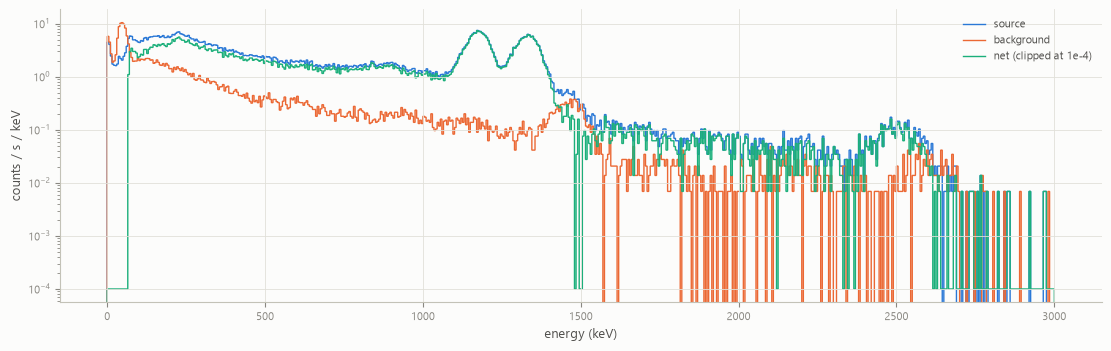

In [58]:
summ = analysis.analyze(ROOT / "data/events/source_first100.h5", TMP / "spec", ROOT / "data/events/background.h5", verbose=False)
print("totals above 120 keV (counts/s):", {k: round(v) for k, v in summ["totals_cps"].items()})
fig, ax = P.figure(1, 1, height_per_row=3.4)
w_ = np.diff(edges_)
ax[0,0].stairs(S_.rate / w_, edges_, label="source"); ax[0,0].stairs(B_.rate / w_, edges_, label="background")
ax[0,0].stairs(np.clip(N_.rate / w_, 1e-4, None), edges_, label="net (clipped at 1e-4)")
ax[0,0].set_yscale("log"); ax[0,0].set_xlabel("energy (keV)"); ax[0,0].set_ylabel("counts / s / keV"); ax[0,0].legend(); plt.show()

---
# Part F: Evaluation tools (not part of the pipeline)

These modules measure how well the pipeline works; they produced the numbers in the docs.

## F1. `restoration.default_configs()` and `restoration.evaluate(...)`
Every combination of pre-processing stages is applied to the **same** pulses (selected on
the raw signal). For each: noise, the baseline just before each pulse, the average tail
after isolated pulses, and Gaussian fits of the ⁶⁰Co peaks with free / fixed baseline, also
split into pulses on an earlier pulse's tail vs clean ones (`docs/baseline-restoration.md`).

In [59]:
from gammaspec import restoration
for name, cfg in restoration.default_configs().items():
    print(f"{name:30s} -> label: {cfg.label()}")

raw                            -> label: raw
lines                          -> label: line_removal
tracker only                   -> label: baseline_tracker
pole-zero                      -> label: pole_zero
lines + pole-zero              -> label: line_removal + pole_zero
lines + pole-zero + tracker    -> label: line_removal + pole_zero + baseline_tracker


## F2. `detection_eval.noise_streams`, `inject`, `_matched`, `_both_found`

* `noise_streams`: pulse-free stretches of the clean signal joined together (**real
  noise**), and the same with **randomised Fourier phases** (**pure noise**): identical
  power spectrum, but any pulse is smeared into noise, so detections in it are false.
* `inject`: adds template pulses at random sub-sample times (optionally a second one d
  samples later).
* `_matched` / `_both_found`: is a detection within ±2 samples of the truth? For pairs,
  two **distinct** detections are required.

In [60]:
from gammaspec import detection_eval
real_n, pure_n, _ = detection_eval.noise_streams(SRC_STORE, Tp, pz, [0, 50])
ns_r = noise.noise_spectrum(real_n[: real_n.size // 512 * 512].reshape(-1, 512), FS)
ns_p = noise.noise_spectrum(pure_n[: pure_n.size // 512 * 512].reshape(-1, 512), FS)
print(f"real noise {real_n.size} samples, rms {real_n.std()*1e3:.3f} mV; pure noise rms {pure_n.std()*1e3:.3f} mV")
print("PSD ratio pure/real at 50, 200, 500 kHz:", np.round(np.interp([5e4, 2e5, 5e5], ns_r.freq_hz, ns_p.psd / ns_r.psd), 2))
yi, ci, Ai = detection_eval.inject(real_n, Tp, [0.003], np.random.default_rng(0), second=(6, 0.03))
found_ = det.detect(yi).index
print("injected", ci.size, "pairs (3 mV then 30 mV, 6 samples apart): first found", detection_eval._matched(found_, np.round(ci).astype(int)).mean().round(3),
      "; both found as two events", detection_eval._both_found(found_, np.round(ci).astype(int), np.round(ci + 6).astype(int)).mean().round(3))

real noise 370944 samples, rms 0.722 mV; pure noise rms 0.722 mV
PSD ratio pure/real at 50, 200, 500 kHz: [1.06 1.   1.01]


injected 926 pairs (3 mV then 30 mV, 6 samples apart): first found 0.982 ; both found as two events 0.982


## F3. `pileup_eval`: the three pile-up tests

* `make_context(template, noise)`: template → pole-zero design → filtered template, decay
  constant, noise autocovariance → `PileupContext`.
* `_robust(errors)`: median (bias) and 1.4826 × MAD (spread) of relative errors.
* `test_template_pairs`: test A. Pairs injected into real noise, **found by the detector**,
  resolved; each estimate divided by the method's estimate of the same noiseless pulse alone.
* `real_isolated_pulses` + `test_real_pairs`: test B. Real isolated pulses added in pairs;
  each estimate divided by the method's estimate of that real pulse alone.
* `test_real_events`: test C. The real pile-up snippets are resolved; the ⁶⁰Co peaks are
  compared with the method's own isolated-pulse peaks.
* `_speed`: time per two-pulse cluster.

A small version of test B:

In [61]:
from gammaspec import pileup_eval
Wr = pileup_eval.real_isolated_pulses(SRC_STORE, Tp, pz, [3, 4])
print("real isolated pulses:", Wr.shape)
Bres, singles = pileup_eval.test_real_pairs(Wr, ctx, np.random.default_rng(0), n_per_d=60)
for d_ in ("4", "10"):
    print(f"separation {d_}: " + ", ".join(f"{m} {100*Bres[d_][m]['second']['bias']:+.1f}/{100*Bres[d_][m]['second']['spread']:.1f}%" for m in pileup.METHODS))

real isolated pulses: (553, 161)


separation 4: tm +2.3/4.5%, hyper +0.2/4.0%, ls +4.7/6.6%, ls_refine +0.2/0.6%, gls_refine +0.1/0.5%, wls_refine +0.2/0.5%
separation 10: tm +1.8/2.7%, hyper -0.4/1.0%, ls +1.0/1.3%, ls_refine +0.2/0.5%, gls_refine +0.1/0.2%, wls_refine +0.1/0.3%
